<a href="https://colab.research.google.com/github/vgadade74/Week1-Data-Analysis/blob/main/E_commerce_data_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np

In [ ]:
df_raw = pd.read_csv('/content/drive/MyDrive/week1_submission (2)/data/raw/ecommerce_india_raw_data.csv')

In [ ]:
df = df_raw.copy()

In [ ]:
print("Dataset Shape:", df.shape)

Dataset Shape: (5040, 11)


In [ ]:
print("Column Info:")
df.info()

Column Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5040 entries, 0 to 5039
Data columns (total 11 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Order ID         5040 non-null   object 
 1   Customer ID      5040 non-null   object 
 2   Product Name     5040 non-null   object 
 3   Category         5040 non-null   object 
 4   Quantity         4965 non-null   float64
 5   Unit Price       4965 non-null   float64
 6   Total Amount     5040 non-null   float64
 7   Order Date       5040 non-null   object 
 8   Payment Mode     4939 non-null   object 
 9   Delivery Status  4940 non-null   object 
 10  City             5040 non-null   object 
dtypes: float64(3), object(8)
memory usage: 433.3+ KB


In [ ]:
df.head()

,Order ID,Customer ID,Product Name,Category,Quantity,Unit Price,Total Amount,Order Date,Payment Mode,Delivery Status,City
0,ORD-IN-14351,CUST-IN-1291,Milton Thermosteel Flask (1L),Home & Kitchen,1.0,890.0,890.0,2024-01-20,Credit Card,Delivered,Ahmedabad
1,ORD-IN-13306,CUST-IN-1906,Sandisk 128GB MicroSD Card,Electronics,1.0,899.0,899.0,2024-01-10,UPI,Delivered,Chennai
2,ORD-IN-11737,CUST-IN-1813,Pigeon 1.5L Electric Kettle,Home & Kitchen,4.0,625.0,2500.0,2024-04-13,NaN,Delivered,Jaipur
3,ORD-IN-13051,CUST-IN-1803,Sandisk 128GB MicroSD Card,Electronics,1.0,899.0,899.0,2024-04-10,UPI,Delivered,Kolkata
4,ORD-IN-13312,CUST-IN-1951,Wakefit Orthopedic Memory Foam Pillow,Home & Kitchen,1.0,999.0,999.0,2024-04-19,UPI,Delivered,Coimbatore


In [ ]:
missing_summary = pd.DataFrame({
    'Missing_Count': df.isnull().sum(),
    'Percentage': (df.isnull().sum() / len(df)) * 100
})

In [ ]:
print("Missing Values Summary:")

Missing Values Summary:


In [ ]:
display(missing_summary[missing_summary['Missing_Count'] > 0])

,Missing_Count,Percentage
Quantity,75,1.488095
Unit Price,75,1.488095
Payment Mode,101,2.003968
Delivery Status,100,1.984127


In [ ]:
df['Quantity'] = df['Quantity'].fillna(df['Quantity'].median())

In [ ]:
df['Delivery Status'] = df['Delivery Status'].fillna('Unknown')

In [ ]:
full_duplicates = df.duplicated().sum()
print(f"Full duplicate rows found: {full_duplicates}")
df = df.drop_duplicates()

Full duplicate rows found: 40


In [ ]:
repeated_orders = df[df.duplicated(subset=['Order ID'], keep=False)]
print(f"Rows with repeated Order IDs: {len(repeated_orders)}")

Rows with repeated Order IDs: 0


In [ ]:

# Enforce Numeric Validity (Quantity > 0, Unit Price > 0)
df = df[df['Quantity'] > 0]
df = df[df['Unit Price'] > 0]

# Recalculate or validate Total Amount if required
df['Total Amount'] = df['Quantity'] * df['Unit Price']

# Standardize Categorical Strings
for col in ['Delivery Status', 'Category', 'Payment Mode', 'City']:
    if col in df.columns:
        df[col] = df[col].astype(str).str.strip().str.title()

In [ ]:
df.to_csv('data/cleaned/cleaned_ecommerce_data.csv', index=False)
print("Cleaned dataset successfully saved.")

OSError: Cannot save file into a non-existent directory: 'data/cleaned'

Computing KPIs

In [ ]:
total_revenue = df['Total Amount'].sum()
total_orders = df['Order ID'].nunique()
average_order_value = total_revenue / total_orders
total_units_sold = df['Quantity'].sum()

top_category = df.groupby('Category')['Total Amount'].sum().idxmax()
top_product = df.groupby('Product Name')['Total Amount'].sum().idxmax()

kpi_data = {
    "KPI": [
        "Total Revenue",
        "Total Orders",
        "Average Order Value (AOV)",
        "Total Units Sold",
        "Top Category (by Revenue)",
        "Best Product (by Revenue)"
    ],
    "Value": [
        f"${total_revenue:,.2f}",
        f"{total_orders:,}",
        f"${average_order_value:,.2f}",
        f"{total_units_sold:,}",
        top_category,
        top_product
    ]
}

kpi_df = pd.DataFrame(kpi_data)
display(kpi_df)

,KPI,Value
0,Total Revenue,"$11,636,691.00"
1,Total Orders,"4,881"
2,Average Order Value (AOV),"$2,384.08"
3,Total Units Sold,"8,040.0"
4,Top Category (by Revenue),Electronics
5,Best Product (by Revenue),Zebronics Soundbar with Subwoofer


In [ ]:
# Monthly Sales Trend
df['Order Date'] = pd.to_datetime(df['Order Date'], format='mixed', dayfirst=True)
df['YearMonth'] = df['Order Date'].dt.to_period('M')
monthly_sales = df.groupby('YearMonth')['Total Amount'].sum().reset_index()
monthly_sales['YearMonth'] = monthly_sales['YearMonth'].astype(str)

# Regional / City Performance
city_perf = df.groupby('City')['Total Amount'].agg(['sum', 'count']).rename(columns={'sum': 'Revenue', 'count': 'Orders'}).sort_values(by='Revenue', ascending=False)
display(city_perf.head())

,Revenue,Orders
City,,
Mumbai,861660.0,340
Pune,839319.0,330
Kochi,823193.0,328
Bengaluru,803149.0,345
Ahmedabad,793897.0,339


In [ ]:
customer_orders = df.groupby('Customer ID')['Order ID'].nunique()
repeat_customers = customer_orders[customer_orders > 1].count()
repeat_ratio = (repeat_customers / df['Customer ID'].nunique()) * 100

print(f"Repeat Customer Percentage: {repeat_ratio:.2f}%")

Repeat Customer Percentage: 93.54%


/tmp/ipykernel_2467/482262021.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=category_sales.values, y=category_sales.index, palette="Blues_r")


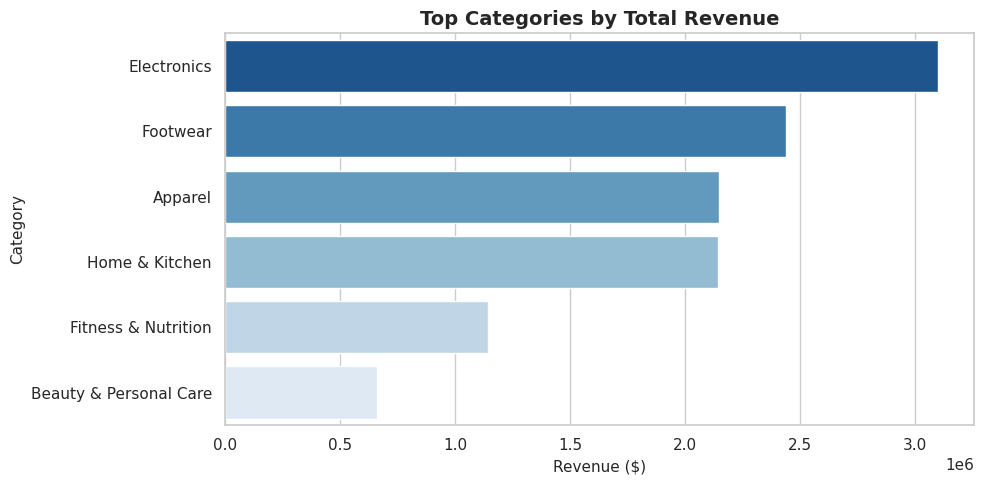

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

plt.figure(figsize=(10, 5))
category_sales = df.groupby('Category')['Total Amount'].sum().sort_values(ascending=False).head(10)
sns.barplot(x=category_sales.values, y=category_sales.index, palette="Blues_r")

plt.title("Top Categories by Total Revenue", fontsize=14, weight='bold')
plt.xlabel("Revenue ($)", fontsize=11)
plt.ylabel("Category", fontsize=11)
plt.tight_layout()
plt.show()

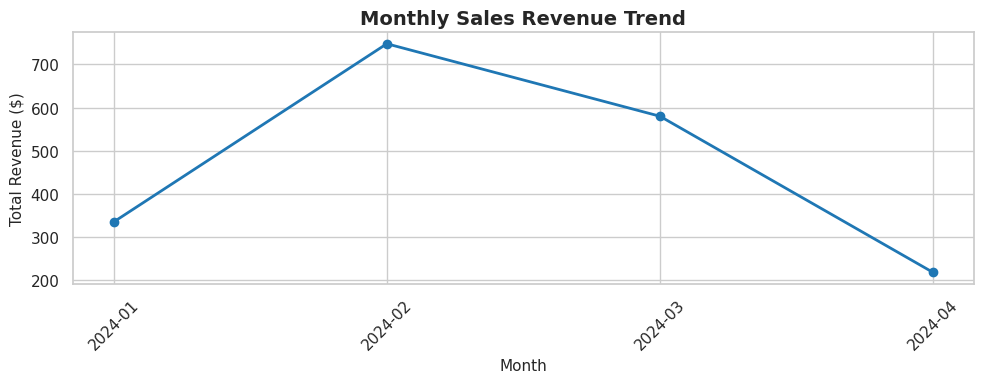

In [ ]:
plt.figure(figsize=(10, 4))
plt.plot(monthly_sales['YearMonth'], monthly_sales['Total Amount'], marker='o', color='#1f77b4', linewidth=2)
plt.title("Monthly Sales Revenue Trend", fontsize=14, weight='bold')
plt.xlabel("Month", fontsize=11)
plt.ylabel("Total Revenue ($)", fontsize=11)
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig('outputs/charts/line_monthly_trend.png')
plt.savefig('screenshots/monthly-sales-trend.png')
plt.show()

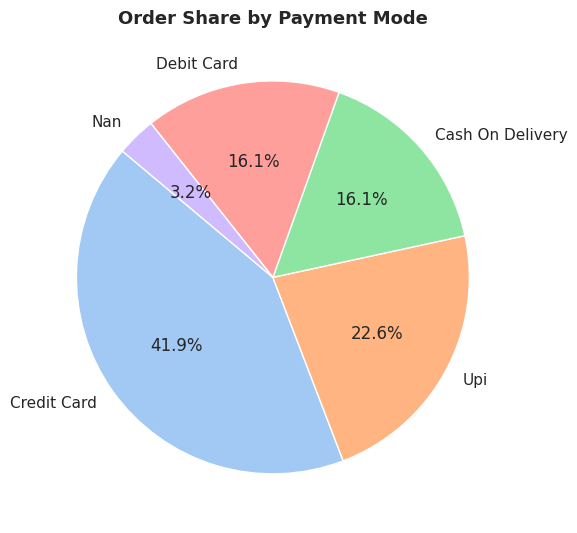

In [ ]:
plt.figure(figsize=(6, 6))
payment_dist = df['Payment Mode'].value_counts()
plt.pie(payment_dist.values, labels=payment_dist.index, autopct='%1.1f%%', startangle=140, colors=sns.color_palette("pastel"))
plt.title("Order Share by Payment Mode", fontsize=13, weight='bold')
plt.tight_layout()
plt.savefig('outputs/charts/pie_payment_mode.png')
plt.show()

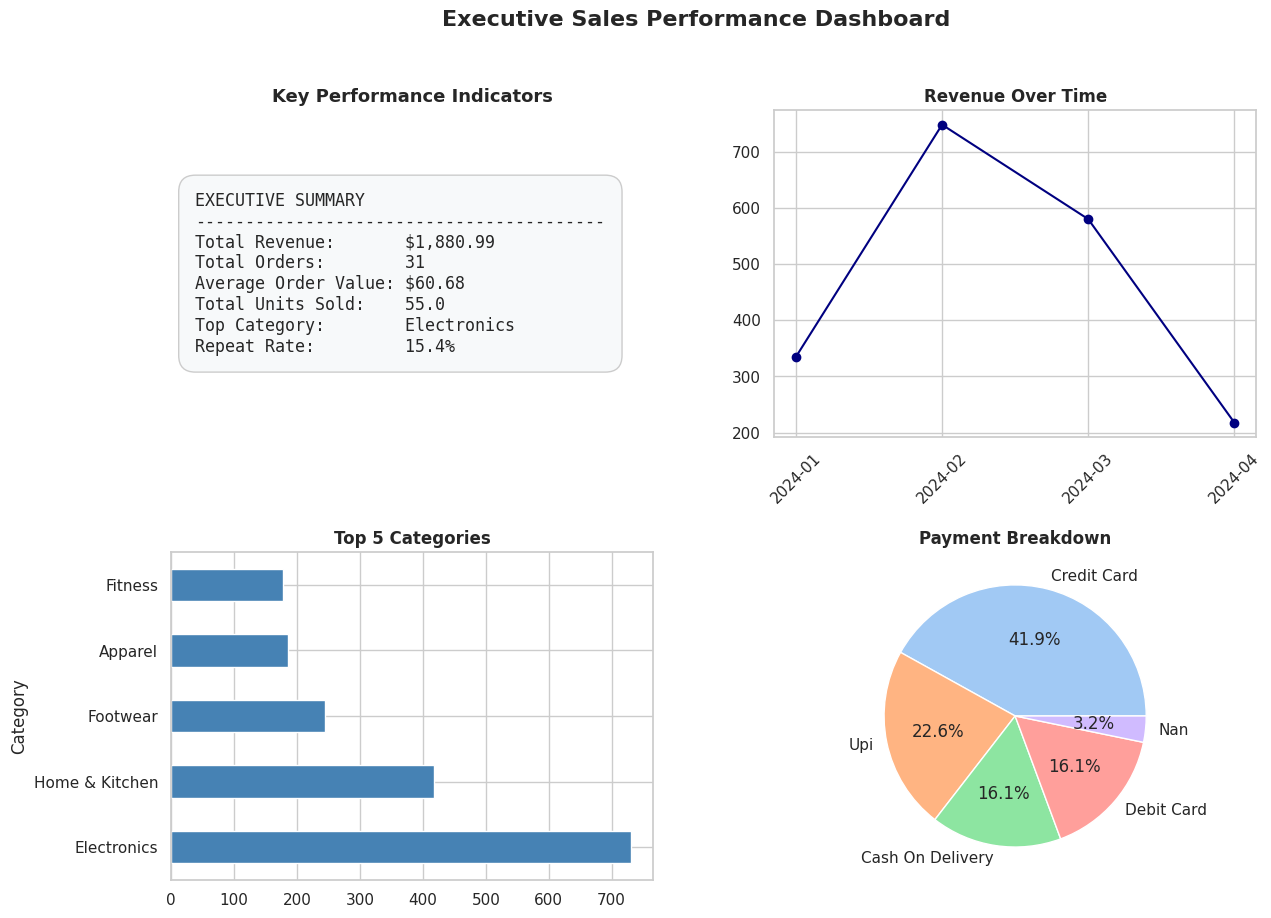

In [ ]:
fig = plt.figure(figsize=(14, 10))
grid = plt.GridSpec(2, 2, figure=fig, hspace=0.35, wspace=0.25)

# Panel 1: KPI Cards
ax1 = fig.add_subplot(grid[0, 0])
ax1.axis('off')
kpi_text = (
    f"EXECUTIVE SUMMARY\n"
    f"-----------------------------------------\n"
    f"Total Revenue:       ${total_revenue:,.2f}\n"
    f"Total Orders:        {total_orders:,}\n"
    f"Average Order Value: ${average_order_value:,.2f}\n"
    f"Total Units Sold:    {total_units_sold:,}\n"
    f"Top Category:        {top_category}\n"
    f"Repeat Rate:         {repeat_ratio:.1f}%"
)
ax1.text(0.05, 0.5, kpi_text, fontsize=12, family='monospace', va='center',
         bbox=dict(boxstyle='round,pad=1', facecolor='#f7f9fa', edgecolor='#cccccc'))
ax1.set_title("Key Performance Indicators", fontsize=13, weight='bold')

# Panel 2: Trend
ax2 = fig.add_subplot(grid[0, 1])
ax2.plot(monthly_sales['YearMonth'], monthly_sales['Total Amount'], marker='o', color='navy')
ax2.set_title("Revenue Over Time", fontsize=12, weight='bold')
ax2.tick_params(axis='x', rotation=45)

# Panel 3: Categories
ax3 = fig.add_subplot(grid[1, 0])
category_sales.head(5).plot(kind='barh', ax=ax3, color='steelblue')
ax3.set_title("Top 5 Categories", fontsize=12, weight='bold')

# Panel 4: Payment Modes
ax4 = fig.add_subplot(grid[1, 1])
ax4.pie(payment_dist.values, labels=payment_dist.index, autopct='%1.1f%%', colors=sns.color_palette("pastel"))
ax4.set_title("Payment Breakdown", fontsize=12, weight='bold')

plt.suptitle("Executive Sales Performance Dashboard", fontsize=16, weight='bold', y=0.98)
plt.savefig('outputs/dashboard/dashboard_mockup.png')
plt.savefig('screenshots/dashboard-mockup.png')
plt.show()

In [ ]:
!pip freeze | grep -E "pandas|numpy|matplotlib|seaborn" > requirements.txt

In [ ]:
!zip -r week1_submission.zip data notebooks outputs reports screenshots requirements.txt

  adding: data/ (stored 0%)
  adding: data/raw/ (stored 0%)
  adding: data/raw/ecommerce_raw_data.csv (deflated 63%)
  adding: data/cleaned/ (stored 0%)
  adding: data/cleaned/cleaned_ecommerce_data.csv (deflated 63%)
  adding: notebooks/ (stored 0%)
  adding: outputs/ (stored 0%)
  adding: outputs/dashboard/ (stored 0%)
  adding: outputs/dashboard/dashboard_mockup.png (deflated 10%)
  adding: outputs/charts/ (stored 0%)
  adding: outputs/charts/pie_payment_mode.png (deflated 5%)
  adding: outputs/charts/line_monthly_trend.png (deflated 8%)
  adding: outputs/charts/bar_category_revenue.png (deflated 20%)
  adding: reports/ (stored 0%)
  adding: screenshots/ (stored 0%)
  adding: screenshots/monthly-sales-trend.png (deflated 8%)
  adding: screenshots/dataset-overview1.png (deflated 14%)
  adding: screenshots/missing-values-report.png (deflated 7%)
  adding: screenshots/dashboard-mockup.png (deflated 10%)
  adding: screenshots/dataset-overview2.png (deflated 4%)
  adding: requirements.tx